# 1 — The layer catalogue and forward verification

Example 1 of the manuscript. A layer viscosity may be a polynomial of degree
at most two or an exponential; the solver matches the layers by continuity of
the velocity and of the stress $K\,\mathrm{d}u/\mathrm{d}z$.

Three checks here: the closed-form constant profile, Abel's identity on every
layer basis, and a ten-layer profile mixing all three polynomial degrees
against an independent Runge-Kutta reference.

In [1]:
using Pkg
Pkg.activate(joinpath(@__DIR__, ".."))
using ELES, LinearAlgebra, Printf
ENV["GKSwstype"] = "100"
using Plots
default(frame = :box, grid = false, size = (820, 300),
        lw = 2, legendfontsize = 7, titlefontsize = 9, guidefontsize = 8)
include(joinpath(@__DIR__, "..", "examples", "reference_shooting.jl"))
include(joinpath(@__DIR__, "..", "examples", "forward_verification.jl"))
using .ForwardVerification
println("layer kinds: ", LAYER_KINDS)

layer kinds: (:constant, :linear, :quadratic, :exponential)


  Activating project at `<package>`


## Constant viscosity against the closed form

For constant $K$ the defect is $-\mathrm{i}\sinh(q(1-z))/\sinh q$ with
$q=\sqrt{\mathrm{i}/K}$. Every kind must reproduce it, because a flat
profile is in all of them.

In [2]:
z = collect(range(0, 1, length = 201))
q = sqrt(1im/0.1)
exact = -1im .* sinh.(q .* (1 .- z)) ./ sinh(q)
for kind in LAYER_KINDS
    model = LayerModel(collect(range(0, 1, length = 11)); kind)
    err = maximum(abs.(ekman_forward(model, fill(0.1, model.nparameters), z) .- exact))
    @printf("%-14s %3d parameters   max error %.2e\n", kind, model.nparameters, err)
end

constant        10 parameters   max error 5.88e-16
linear          11 parameters   max error 5.88e-16
quadratic       21 parameters   max error 5.88e-16
exponential     11 parameters   max error 6.09e-16


## A smooth ten-layer profile of mixed degree

Degrees $(2,1,2,1,2,1,1,2,0,0)$: four general quadratic layers, four affine
and two constant, with thirteen parameters. The viscosity and its first
derivative are continuous across every interface. The idealized profile
increases from the surface to a single interior maximum and decreases to a
small positive background aloft. The shared specification is
`data/figure1_profile.csv`.


In [3]:
configuration = figure1_configuration()
edges, degrees = configuration.edges, configuration.kinds
model, values = configuration.model, configuration.values
@printf("parameters: %d (= 9 knots + 4 midpoints)\n", model.nparameters)
solution = solve_layered(model, values, 1im, -1.0im, 0.0im)
jumps = interface_residuals(solution)
@printf("interface jump in W        %.2e\n", jumps.value)
@printf("interface jump in K dW/dz  %.2e\n", jumps.flux)
@printf("retained Taylor tail       %.2e\n", series_tail(solution))

parameters: 13 (= 9 knots + 4 midpoints)
interface jump in W        1.11e-16
interface jump in K dW/dz  6.94e-18
retained Taylor tail       6.72e-34


`series_tail` is the diagnostic to watch: it inspects a degree-sized window of
retained Taylor coefficients, normalized per basis. It is a diagnostic rather
than an error bound; compare orders or partitions as well.

In [4]:
reference = reference_field(model, values, 1im, -1.0im, 0.0im, z)
@printf("versus independent RK4 shooting   %.2e\n",
        maximum(abs.(field(solution, z) .- reference)))
high = solve_layered(model, values, 1im, -1.0im, 0.0im; order = 240)
@printf("order 160 versus order 240        %.2e\n",
        maximum(abs.(field(solution, z) .- field(high, z))))

versus independent RK4 shooting   1.47e-12
order 160 versus order 240        0.00e+00


## Abel's identity

For $(KW')'=\lambda W$ the product of $K$ and the Wronskian of the two
fundamental solutions is constant on each layer, and nonzero when the pair is
independent. This tests the bases without differencing the solution.

In [5]:
for k in eachindex(degrees)
    lo, hi = model.interfaces[k], model.interfaces[k+1]
    half = (hi - lo)/2
    basis = solution.bases[k]
    order = size(basis, 1) - 1
    products = map(range(lo + 1e-9, hi - 1e-9, length = 201)) do zz
        t = (zz - (lo + hi)/2)/half
        value = transpose(basis)*(t .^ (0:order))
        slope = transpose(basis[2:end, :])*((1:order) .* t .^ (0:order-1))/half
        w = value[1]*slope[2] - value[2]*slope[1]
        (ELES._Kat(solution.kcoefs[k], t)*w, w)
    end
    scaled = first.(products)
    @printf("layer %2d (%-10s)  K*Wronskian varies by %.1e   min|W| %.3f\n",
            k, degrees[k], maximum(abs.(scaled .- scaled[1]))/abs(scaled[1]),
            minimum(abs.(last.(products))))
end

layer  1 (quadratic )  K*Wronskian varies by 1.1e-15   min|W| 13.261
layer  2 (linear    )  K*Wronskian varies by 9.3e-16   min|W| 16.216
layer  3 (quadratic )  K*Wronskian varies by 7.8e-16   min|W| 13.153
layer  4 (linear    )  K*Wronskian varies by 5.6e-16   min|W| 18.605
layer  5 (quadratic )  K*Wronskian varies by 6.5e-16   min|W| 11.644
layer  6 (linear    )  K*Wronskian varies by 5.8e-16   min|W| 10.765
layer  7 (linear    )  K*Wronskian varies by 6.6e-16   min|W| 15.821
layer  8 (quadratic )  K*Wronskian varies by 7.2e-16   min|W| 14.615
layer  9 (constant  )  K*Wronskian varies by 3.3e-16   min|W| 80.000
layer 10 (constant  )  K*Wronskian varies by 3.3e-16   min|W| 80.000


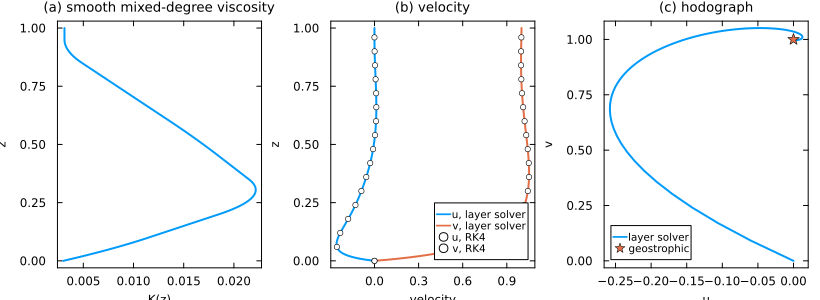

In [6]:
velocity = field(solution, z) .+ 1im            # add the geostrophic (0,1)
ref = reference .+ 1im
marks = 1:12:length(z)
plot(
  plot(viscosity(solution, z), z; xlabel = "K(z)", ylabel = "z",
       title = "(a) smooth mixed-degree viscosity", legend = false),
  begin
    p = plot(real.(velocity), z; label = "u, layer solver", xlabel = "velocity",
             ylabel = "z", title = "(b) velocity")
    plot!(p, imag.(velocity), z; label = "v, layer solver")
    scatter!(p, real.(ref)[marks], z[marks]; label = "u, RK4", ms = 3, msw = 1,
             mc = :white)
    scatter!(p, imag.(ref)[marks], z[marks]; label = "v, RK4", ms = 3, msw = 1,
             mc = :white)
  end,
  begin
    p = plot(real.(velocity), imag.(velocity); label = "layer solver",
             xlabel = "u", ylabel = "v", title = "(c) hodograph")
    scatter!(p, [0.0], [1.0]; label = "geostrophic", ms = 6, m = :star5)
  end;
  layout = (1, 3))